### Lesson 5 Project

### Put Lessons 1 - 5 together

#### 2000 samples
#### 10 features
#### 2 classes

In [1]:
# import libraries
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import(
    TensorDataset,
    DataLoader,
    random_split
)

from sklearn.datasets import make_classification


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 807, in start
    self.io_lo

In [2]:
# set device config
device = torch.device("cpu")

print("Device: ", device)

Device:  cpu


In [3]:
# create dataset
X, y = make_classification(
    n_samples=2000,
    n_features=10,
    n_informative=7,
    n_redundant=2,
    n_classes=2,
    random_state=42
)

In [4]:
# convert tensorDataset
X = torch.tensor(
    X,
    dtype=torch.float32
)

y = torch.tensor(
    y,
    dtype=torch.float32
).reshape(-1, 1)

In [5]:
# create dataset object
dataset = TensorDataset(
    X,
    y
)

In [6]:
# Data Splitting (70/15/15)
train_size = int(
    0.70 * len(dataset)
)

val_size = int(
    0.15 * len(dataset)
)

test_size = int(
    len(dataset)
    - train_size
    - val_size
)

In [7]:
# use generator
generator = torch.Generator().manual_seed(42)

# random_split the dataset
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator
)

In [8]:
# create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

In [9]:
# define the Pytorch Neural Network Model
class BinaryClassifier(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)

        )

    def forward(self, x):
        return self.network(x)

In [10]:
model = BinaryClassifier(
    input_dim=X.shape[1]
).to(device)

In [11]:
# loss and optimizer
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [12]:
# train_step
def train_step(
    model,
    dataloader,
    loss_fn,
    optimizer,
    device
):

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for X, y in dataloader:

        X = X.to(device)
        y = y.to(device)

        # clear previous gradients
        optimizer.zero_grad()

        # forward pass
        logits = model(X)

        # calculate loss
        loss = loss_fn(logits, y)

        # Backpropagation
        loss.backward()

        # update parameters
        optimizer.step()

        # track loss
        train_loss += loss.item()

        # predictions
        probabilities = torch.sigmoid(logits)

        predictions = (
           probabilities >= 0.5
       ).float()

        train_correct += (
            predictions == y
        ).sum().item()

        train_total += y.numel()

    train_loss /= len(dataloader)

    train_accuracy = (
        train_correct / train_total
    )

    return train_loss, train_accuracy

In [13]:
# validation step
def validation_step(
        model,
        dataloader,
        loss_fn,
        device
):

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total =0

    with torch.no_grad():

        for X, y in dataloader:

            X = X.to(device)
            y = y.to(device)

            logits = model(X)

            loss = loss_fn(
                logits,
                y
            )

            val_loss += loss.item()

            probabilities = torch.sigmoid(
                logits
            )

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == y
            ).sum().item()

            val_total += y.numel()

    val_loss /= len(dataloader)

    val_accuracy = (
        val_correct / val_total
    )

    return val_loss, val_accuracy

In [14]:
# main training loop
for epoch in range(10):

    train_loss, train_acc = train_step(
        model=model,
        dataloader=train_loader,
        loss_fn=loss_fn,
        optimizer=optimizer,
        device=device
    )

    val_loss, val_acc = validation_step(
        model=model,
        dataloader=val_loader,
        loss_fn=loss_fn,
        device=device
    )

    # print the training results
    print(
        f"Epoch {epoch + 1}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/10 | Train Loss: 0.5946 | Train Acc: 0.7314 | Val Loss: 0.4373 | Val Acc: 0.8700
Epoch 2/10 | Train Loss: 0.3816 | Train Acc: 0.8407 | Val Loss: 0.2888 | Val Acc: 0.8967
Epoch 3/10 | Train Loss: 0.3109 | Train Acc: 0.8714 | Val Loss: 0.2369 | Val Acc: 0.9133
Epoch 4/10 | Train Loss: 0.2831 | Train Acc: 0.8821 | Val Loss: 0.2217 | Val Acc: 0.9133
Epoch 5/10 | Train Loss: 0.2526 | Train Acc: 0.8957 | Val Loss: 0.2066 | Val Acc: 0.9267
Epoch 6/10 | Train Loss: 0.2388 | Train Acc: 0.9057 | Val Loss: 0.1953 | Val Acc: 0.9300
Epoch 7/10 | Train Loss: 0.2476 | Train Acc: 0.8993 | Val Loss: 0.1654 | Val Acc: 0.9433
Epoch 8/10 | Train Loss: 0.2411 | Train Acc: 0.8971 | Val Loss: 0.1696 | Val Acc: 0.9467
Epoch 9/10 | Train Loss: 0.2237 | Train Acc: 0.9143 | Val Loss: 0.1628 | Val Acc: 0.9433
Epoch 10/10 | Train Loss: 0.2122 | Train Acc: 0.9129 | Val Loss: 0.1592 | Val Acc: 0.9467


In [15]:
# reusable train() function
def train(
    model,
    train_loader,
    val_loader,
    loss_fn,
    optimizer,
    epochs,
    device,
    pateince=5
):

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    patience_counter = 0


    for epoch in range(epochs):

        # training
        train_loss, train_acc = train_step(
            model,
            train_loader,
            loss_fn,
            optimizer,
            device
        )
    
        # validation
        val_loss, val_acc = validation_step(
            model,
            val_loader,
            loss_fn,
            device
        )

        # save history
        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_acc
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
        )

        # check model improvement
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            patience_counter = 0

            # save model
            torch.save(
                model.save_dict(),
                "05_project_best_model.pth"
            )

            print(
                "✓ Best Model Saved"
            )

        else:

            patience_counter += 1


        # early_stopping

        if patience_counter >= patience:

            print(
                "Early Stopping Triggered."
            )

            break

    return history

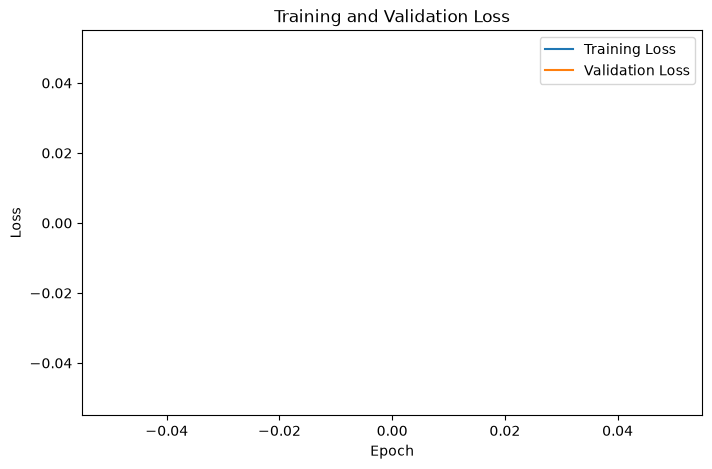

In [16]:
# import training curves
history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

# plot training and validation plots
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

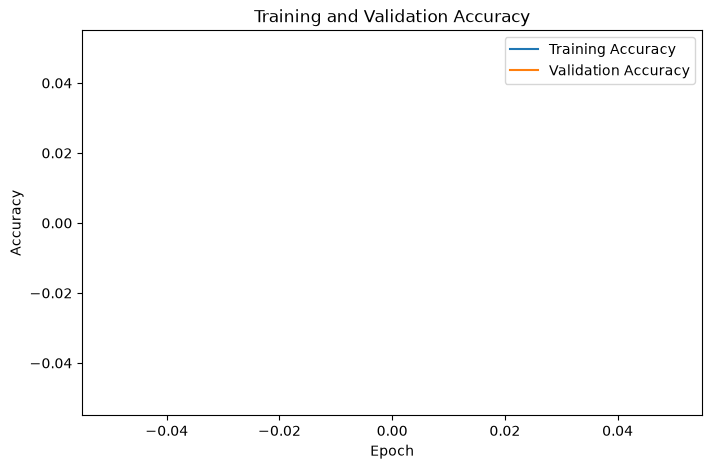

In [17]:
# accuaracy curve
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()

plt.show()

In [18]:
# test evaluation
def evaluate(
    model,
    dataloader,
    loss_fn,
    device
):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for X, y in dataloader:

            X = X.to(device)
            y = y.to(device)

            logits = model(X)

            loss = model(X)

            loss = loss_fn(
                logits,
                y
            )

            total_loss += loss.item()

            probabilities = torch.sigmoid(
                logits
            )

            predictions = (
                probabilities >= 0.5
            ).float()

            correct += (
                predictions == y
            ).sum().item()

            total += y.numel()

    average_loss = (
        total_loss / 
        len(dataloader)
    )

    accuracy = (
        correct / 
        total
    )

    return average_loss, accuracy

In [19]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    loss_fn,
    device
)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_accuracy:.4f}"
)

Test Loss: 0.1590
Test Accuracy: 0.9633


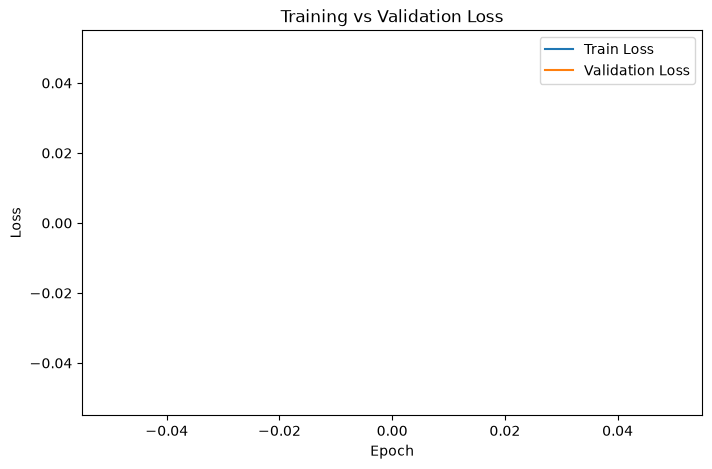

In [20]:
# plot training history

# Loss
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

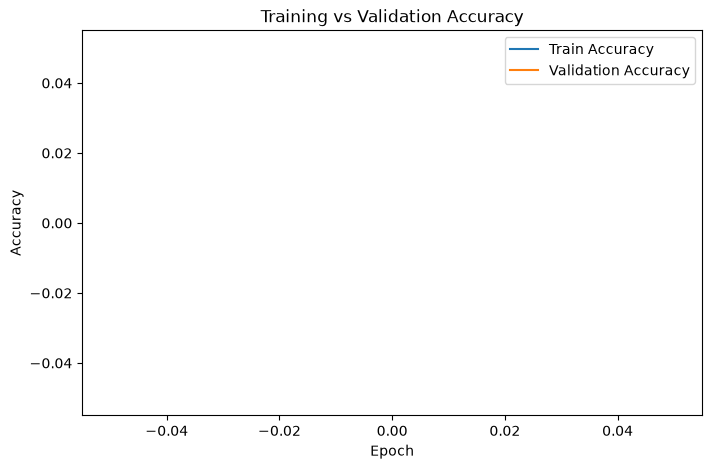

In [21]:
# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()

plt.show()

In [22]:
# # load the best model
# model.load_state_dict(
#     torch.load(
#         "05_project_best_model.pth",
#         map_location=device,
#         weights_only=True
#     )
# )

In [23]:
# history = train(
#     model=model,
#     train_loader=train_loader,
#     val_loader=val_loader,
# )

In [24]:
# # model training
# history = train(
#     model=model,
#     train_loader=train_loader,
#     val_loader=val_loader,
#     loss_fn=loss_fn,
#     optimizer=optimizer,
#     epochs=50,
#     device=device,
#     patience=5
# )